In [ ]:
# 	ACC, HR, BVP

In [31]:
import pandas as pd
import numpy as np
from pathlib import Path

In [44]:
# ==========================================
# 1. FUNKCJA WCZYTUJĄCA SYGNAŁY EMPATICA E4
# ==========================================

def load_signal(folder, filename, columns):

    raw = pd.read_csv(folder / filename, header=None)

    # Czas rozpoczęcia pomiaru
    start_time = pd.to_datetime(raw.iloc[0, 0], utc=True)

    # Częstotliwość próbkowania
    fs = float(raw.iloc[1, 0])

    # Wartości sygnału
    values = raw.iloc[2:, :len(columns)].apply(
        pd.to_numeric, errors="coerce"
    ).reset_index(drop=True)

    # Indeksy czasowe próbek
    timestamps = (
        start_time
        + pd.to_timedelta(np.arange(len(values)) / fs, unit="s")
    )

    values.index = timestamps
    values.columns = columns

    return values

In [45]:
# ==========================================
# 2. FUNKCJA WCZYTUJĄCA CAŁĄ SESJĘ
# ==========================================

def load_session(folder, session_name, label):

    # Wczytanie sygnałów
    acc = load_signal(folder, "ACC.csv", ["ACC_x", "ACC_y", "ACC_z"])
    bvp = load_signal(folder, "BVP.csv", ["BVP"])
    eda = load_signal(folder, "EDA.csv", ["EDA"])
    temp = load_signal(folder, "TEMP.csv", ["TEMP"])
    hr = load_signal(folder, "HR.csv", ["HR"])

    # Synchronizacja sygnałów do 1 Hz
    df = pd.concat(
        [
            acc.resample("1s").mean(),
            bvp.resample("1s").mean(),
            eda.resample("1s").mean(),
            temp.resample("1s").mean(),
            hr.resample("1s").mean()
        ],
        axis=1
    )

    # Wypadkowa przyspieszenia
    df["ACC_magnitude"] = np.sqrt(
        df["ACC_x"]**2 +
        df["ACC_y"]**2 +
        df["ACC_z"]**2
    )

    # Etykiety
    df["session"] = session_name
    df["label"] = label
    df["label_encoded"] = 0 if label == "AEROBIC" else 1

    return df

In [60]:

# ==========================================
# 3. WCZYTANIE WSZYSTKICH UCZESTNIKÓW
# ==========================================

all_data = []

sessions = {
    "AEROBIC": 0,
    "ANAEROBIC": 1
}

for session_name, label in sessions.items():

    session_path = BASE_DIR / session_name

    participants = sorted(
        p for p in session_path.iterdir() if p.is_dir()
    )

    print(f"\nPrzetwarzanie {session_name}...")

    for participant_folder in participants:

        participant = participant_folder.name

        try:
            df = load_session(
                participant_folder,
                session_name,
                session_name
            )

            df["participant"] = participant

            # Zachowanie czasu pomiaru jako kolumny
            df.index.name = "timestamp"
            df = df.reset_index()

            all_data.append(df)

            print(f"OK: {participant}")

        except Exception as e:
            print(f"Pominięto {participant}: {e}")



Przetwarzanie AEROBIC...
OK: f01
OK: f02
OK: f03
OK: f04
OK: f05
OK: f06
OK: f07
OK: f08
OK: f09
OK: f10
OK: f11
OK: f12
OK: f13
OK: S01
OK: S02
OK: S03
OK: S04
OK: S05
OK: S06
OK: S07
OK: S08
OK: S09
OK: S10
OK: S11_a
OK: S11_b
OK: S13
OK: S14
OK: S15
OK: S16
OK: S17
OK: S18

Przetwarzanie ANAEROBIC...
OK: f01
OK: f02
OK: f03
OK: f04
OK: f05
OK: f06
OK: f07
OK: f08
OK: f09
OK: f10
OK: f11
OK: f12
OK: f13
OK: S01
OK: S02
OK: S03
OK: S04
OK: S05
OK: S06
OK: S07
OK: S08
OK: S09
OK: S10
OK: S11
OK: S12
OK: S13
OK: S14
OK: S15
OK: S16_a
OK: S16_b
OK: S17
OK: S18


In [61]:
# ==========================================
# 4. POŁĄCZENIE WSZYSTKICH DANYCH
# ==========================================

df_all = pd.concat(all_data, ignore_index=True)

# Uporządkowanie kolumn
df_all = df_all[
    [
        "timestamp",
        "participant",
        "session",
        "ACC_x",
        "ACC_y",
        "ACC_z",
        "ACC_magnitude",
        "BVP",
        "EDA",
        "TEMP",
        "HR",
        "label",
        "label_encoded"
    ]
]

In [62]:
# ==========================================
# 5. PODSTAWOWE INFORMACJE
# ==========================================

print("\n========== PODSUMOWANIE ==========")

print("Wymiary:", df_all.shape)

print("\nLiczba próbek dla klas:")
print(df_all["label"].value_counts())

print("\nLiczba uczestników:")
print(df_all.groupby("session")["participant"].nunique())

print("\nBrakujące wartości:")
print(df_all.isna().sum())

print("\nPierwsze rekordy:")
print(df_all.head())


========== PODSUMOWANIE ==========
Wymiary: (115963, 13)

Liczba próbek dla klas:
label
AEROBIC      65875
ANAEROBIC    50088
Name: count, dtype: int64

Liczba uczestników:
session
AEROBIC      31
ANAEROBIC    32
Name: participant, dtype: int64

Brakujące wartości:
timestamp          0
participant        0
session            0
ACC_x             36
ACC_y             36
ACC_z             36
ACC_magnitude     36
BVP               28
EDA               91
TEMP              79
HR               673
label              0
label_encoded      0
dtype: int64

Pierwsze rekordy:
                  timestamp participant  session     ACC_x     ACC_y  \
0 2013-07-04 12:06:34+00:00         f01  AEROBIC  20.59375  -3.31250   
1 2013-07-04 12:06:35+00:00         f01  AEROBIC  25.53125 -38.12500   
2 2013-07-04 12:06:36+00:00         f01  AEROBIC  22.40625 -53.00000   
3 2013-07-04 12:06:37+00:00         f01  AEROBIC  51.53125  27.81250   
4 2013-07-04 12:06:38+00:00         f01  AEROBIC  58.03125  28.71875

In [64]:
hr_nan = df_all.loc[
    df_all["HR"].isna(),
    ["timestamp", "participant", "session"]
]

print(hr_nan.to_string(index=False))

                timestamp participant   session
2013-07-04 12:06:34+00:00         f01   AEROBIC
2013-07-04 12:06:35+00:00         f01   AEROBIC
2013-07-04 12:06:36+00:00         f01   AEROBIC
2013-07-04 12:06:37+00:00         f01   AEROBIC
2013-07-04 12:06:38+00:00         f01   AEROBIC
2013-07-04 12:06:39+00:00         f01   AEROBIC
2013-07-04 12:06:40+00:00         f01   AEROBIC
2013-07-04 12:06:41+00:00         f01   AEROBIC
2013-07-04 12:06:42+00:00         f01   AEROBIC
2013-07-04 12:06:43+00:00         f01   AEROBIC
2013-07-04 12:51:33+00:00         f01   AEROBIC
2013-07-04 13:23:46+00:00         f02   AEROBIC
2013-07-04 13:23:47+00:00         f02   AEROBIC
2013-07-04 13:23:48+00:00         f02   AEROBIC
2013-07-04 13:23:49+00:00         f02   AEROBIC
2013-07-04 13:23:50+00:00         f02   AEROBIC
2013-07-04 13:23:51+00:00         f02   AEROBIC
2013-07-04 13:23:52+00:00         f02   AEROBIC
2013-07-04 13:23:53+00:00         f02   AEROBIC
2013-07-04 13:23:54+00:00         f02   

In [66]:
# Sortowanie danych chronologicznie
df_all = df_all.sort_values(
    ["participant", "session", "timestamp"]
).copy()

# Uzupełnianie brakujących wartości HR interpolacją liniową
df_all["HR"] = (
    df_all.groupby(["participant", "session"])["HR"]
    .transform(lambda x: x.interpolate(
        method="linear",
        limit_area="inside"
    ))
)

# Usunięcie pozostałych wierszy zawierających NaN
df_all = df_all.dropna().reset_index(drop=True)

In [67]:
# ==========================================
# 5. PODSTAWOWE INFORMACJE
# ==========================================

print("\n========== PODSUMOWANIE ==========")

print("Wymiary:", df_all.shape)

print("\nLiczba próbek dla klas:")
print(df_all["label"].value_counts())

print("\nLiczba uczestników:")
print(df_all.groupby("session")["participant"].nunique())

print("\nBrakujące wartości:")
print(df_all.isna().sum())

print("\nPierwsze rekordy:")
print(df_all.head())


========== PODSUMOWANIE ==========
Wymiary: (115200, 13)

Liczba próbek dla klas:
label
AEROBIC      65500
ANAEROBIC    49700
Name: count, dtype: int64

Liczba uczestników:
session
AEROBIC      31
ANAEROBIC    32
Name: participant, dtype: int64

Brakujące wartości:
timestamp        0
participant      0
session          0
ACC_x            0
ACC_y            0
ACC_z            0
ACC_magnitude    0
BVP              0
EDA              0
TEMP             0
HR               0
label            0
label_encoded    0
dtype: int64

Pierwsze rekordy:
                  timestamp participant  session     ACC_x     ACC_y  \
0 2013-03-03 17:43:47+00:00         S01  AEROBIC  53.75000  24.00000   
1 2013-03-03 17:43:48+00:00         S01  AEROBIC  53.59375  24.18750   
2 2013-03-03 17:43:49+00:00         S01  AEROBIC  54.09375  23.71875   
3 2013-03-03 17:43:50+00:00         S01  AEROBIC  53.46875  24.87500   
4 2013-03-03 17:43:51+00:00         S01  AEROBIC  52.84375  24.96875   

      ACC_z  ACC_magn

In [68]:
import numpy as np
import pandas as pd

SIGNALS = [
    "ACC_x", "ACC_y", "ACC_z", "ACC_magnitude",
    "BVP", "EDA", "TEMP", "HR"
]

WINDOW_SIZE = 10

features_list = []

# Osobno przetwarzamy każdego uczestnika i każdą sesję
for (participant, session), group in df_all.groupby(["participant", "session"]):

    group = group.sort_values("timestamp").reset_index(drop=True)

    for start in range(0, len(group) - WINDOW_SIZE + 1, WINDOW_SIZE):

        window = group.iloc[start:start + WINDOW_SIZE]

        # Pomijamy okna, w których występują przerwy czasowe
        time_diff = window["timestamp"].diff().dt.total_seconds().dropna()

        if not (time_diff == 1).all():
            continue

        features = {}

        for signal in SIGNALS:
            values = window[signal]

            features[f"{signal}_mean"] = values.mean()
            features[f"{signal}_std"] = values.std()
            features[f"{signal}_min"] = values.min()
            features[f"{signal}_max"] = values.max()

        features["label_encoded"] = window["label_encoded"].iloc[0]
        features["participant"] = participant
        features["session"] = session

        features_list.append(features)

df_features = pd.DataFrame(features_list)

print("Liczba okien:", len(df_features))
print(df_features["session"].value_counts())

Liczba okien: 11490
session
AEROBIC      6536
ANAEROBIC    4954
Name: count, dtype: int64


In [69]:
from sklearn.model_selection import train_test_split

X = df_features.drop(columns=[
    "label_encoded", "participant", "session"
])

y = df_features["label_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Zbiór treningowy:", X_train.shape)
print("Zbiór testowy:", X_test.shape)

Zbiór treningowy: (9192, 32)
Zbiór testowy: (2298, 32)


In [70]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [71]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["AEROBIC", "ANAEROBIC"]
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9634464751958225

Classification report:
              precision    recall  f1-score   support

     AEROBIC       0.97      0.97      0.97      1307
   ANAEROBIC       0.96      0.96      0.96       991

    accuracy                           0.96      2298
   macro avg       0.96      0.96      0.96      2298
weighted avg       0.96      0.96      0.96      2298


Confusion matrix:
[[1265   42]
 [  42  949]]


In [72]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance.head(15))

               feature  importance
7            ACC_y_max    0.060201
4           ACC_y_mean    0.056360
24           TEMP_mean    0.053088
27            TEMP_max    0.050633
6            ACC_y_min    0.050243
26            TEMP_min    0.050141
12  ACC_magnitude_mean    0.046793
10           ACC_z_min    0.040457
3            ACC_x_max    0.039871
8           ACC_z_mean    0.039553
0           ACC_x_mean    0.039060
23             EDA_max    0.036867
20            EDA_mean    0.035862
2            ACC_x_min    0.034362
22             EDA_min    0.032875


In [78]:
import joblib

# Zapis modelu
joblib.dump(model, "activity_detection.pkl")

['activity_detection.pkl']

In [79]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

WINDOW_SIZE = 10

SIGNALS = [
    "ACC_x", "ACC_y", "ACC_z", "ACC_magnitude",
    "BVP", "EDA", "TEMP", "HR"
]

features_list = []

for (participant, session), group in df_all.groupby(
    ["participant", "session"]
):
    group = group.sort_values("timestamp").reset_index(drop=True)

    for start in range(0, len(group) - WINDOW_SIZE + 1, WINDOW_SIZE):

        window = group.iloc[start:start + WINDOW_SIZE]

        # Pomijamy nieciągłe okna
        time_diff = window["timestamp"].diff().dt.total_seconds().dropna()

        if not (time_diff == 1).all():
            continue

        features = {}

        for signal in SIGNALS:
            values = window[signal]

            features[f"{signal}_mean"] = values.mean()
            features[f"{signal}_std"] = values.std()
            features[f"{signal}_min"] = values.min()
            features[f"{signal}_max"] = values.max()

        features["timestamp"] = window["timestamp"].iloc[0]
        features["participant"] = participant
        features["session"] = session
        features["label_encoded"] = window["label_encoded"].iloc[0]

        features_list.append(features)

df_features = pd.DataFrame(features_list)

df_features = df_features.sort_values(
    ["participant", "session", "timestamp"]
).reset_index(drop=True)

print("Liczba okien:", len(df_features))

Liczba okien: 11490


In [82]:
BASELINE_SECONDS = 60

detection_results = []

for participant, test_df in test_data.items():

    # Pobranie pierwszej minuty danych uczestnika
    person_raw = df_all[
        df_all["participant"] == participant
    ]

    baseline_data = person_raw[
        person_raw["timestamp"] <
        person_raw.groupby("session")["timestamp"].transform("min")
        + pd.Timedelta(seconds=BASELINE_SECONDS)
    ]

    hr_baseline = baseline_data["HR"].median()

    if pd.isna(hr_baseline) or hr_baseline <= 0:
        continue

    # Detekcja osobno dla każdej sesji
    for session, group in test_df.groupby("session"):

        detected = detect_activity(
            group,
            hr_baseline=hr_baseline,
            hr_increase=1.15,
            min_motion_std=0.02,
            window_count=4,
            required_windows=3,
            stop_windows=3
        )

        # Klasyfikacja AEROBIC / ANAEROBIC
        # tylko wtedy, gdy aktywność została potwierdzona
        detected["activity_type"] = np.where(
            detected["is_active"],
            detected["prediction"].map({
                0: "AEROBIC",
                1: "ANAEROBIC"
            }),
            "REST"
        )

        detected["participant"] = participant
        detected["session"] = session

        detection_results.append(detected)

df_detection = pd.concat(
    detection_results,
    ignore_index=True
)

print(df_detection[
    [
        "timestamp",
        "participant",
        "session",
        "HR_mean",
        "ACC_magnitude_std",
        "prediction",
        "is_active",
        "activity_type"
    ]
].head(30))

                   timestamp participant  session  HR_mean  ACC_magnitude_std  \
0  2013-03-03 18:10:47+00:00         S01  AEROBIC  102.523           0.367152   
1  2013-03-03 18:10:57+00:00         S01  AEROBIC   99.789           0.206161   
2  2013-03-03 18:11:07+00:00         S01  AEROBIC   96.694           0.520411   
3  2013-03-03 18:11:17+00:00         S01  AEROBIC   95.489           0.455456   
4  2013-03-03 18:11:27+00:00         S01  AEROBIC   95.400           0.350336   
5  2013-03-03 18:11:37+00:00         S01  AEROBIC   97.528           0.336999   
6  2013-03-03 18:11:47+00:00         S01  AEROBIC   99.909           0.121265   
7  2013-03-03 18:11:57+00:00         S01  AEROBIC  102.668           0.548367   
8  2013-03-03 18:12:07+00:00         S01  AEROBIC  108.401           0.920930   
9  2013-03-03 18:12:17+00:00         S01  AEROBIC  112.690           0.462050   
10 2013-03-03 18:12:27+00:00         S01  AEROBIC  116.481           0.175094   
11 2013-03-03 18:12:37+00:00

In [83]:
summary = (
    df_detection.groupby(
        ["participant", "session", "activity_type"]
    )
    .size()
    .reset_index(name="number_of_windows")
)

summary["duration_seconds"] = (
    summary["number_of_windows"] * WINDOW_SIZE
)

print(summary.to_string(index=False))

participant   session activity_type  number_of_windows  duration_seconds
        S01   AEROBIC       AEROBIC                 20               200
        S01   AEROBIC          REST                 21               210
        S01 ANAEROBIC          REST                 23               230
        S02   AEROBIC       AEROBIC                 38               380
        S02   AEROBIC          REST                  3                30
        S02 ANAEROBIC     ANAEROBIC                  5                50
        S02 ANAEROBIC          REST                 18               180
        S03   AEROBIC       AEROBIC                 26               260
        S03   AEROBIC          REST                  3                30
        S03 ANAEROBIC       AEROBIC                  8                80
        S03 ANAEROBIC     ANAEROBIC                 14               140
        S03 ANAEROBIC          REST                  3                30
        S04   AEROBIC       AEROBIC                

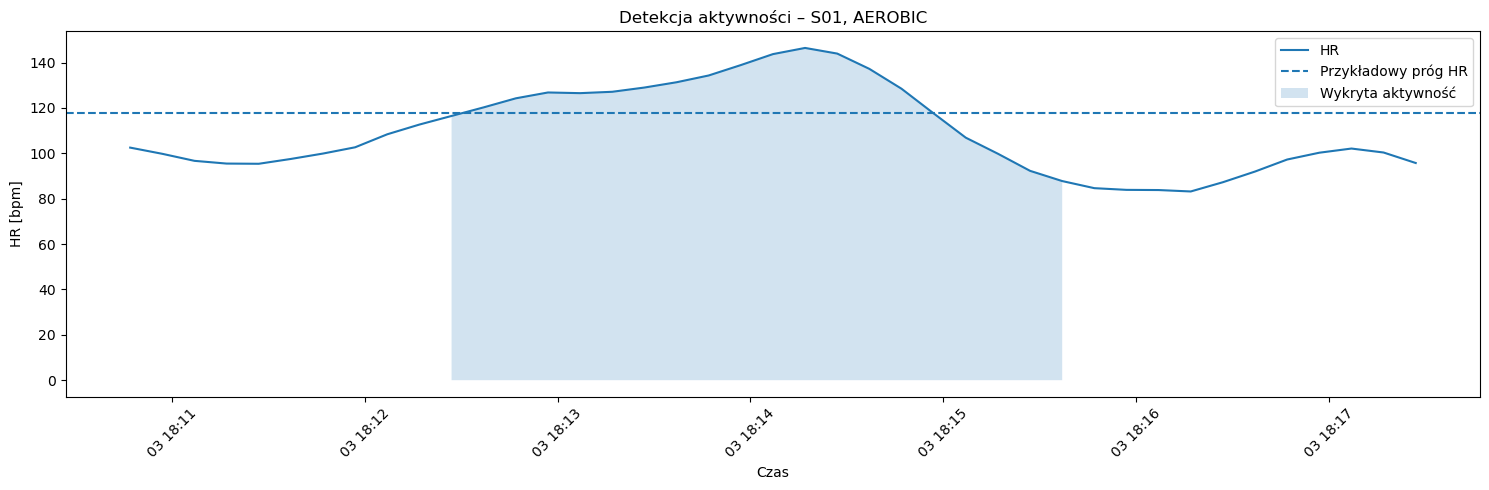

In [85]:
import matplotlib.pyplot as plt

participant = df_detection["participant"].iloc[0]
session = df_detection["session"].iloc[0]

plot_data = df_detection[
    (df_detection["participant"] == participant) &
    (df_detection["session"] == session)
].sort_values("timestamp")

plt.figure(figsize=(15, 5))

plt.plot(
    plot_data["timestamp"],
    plot_data["HR_mean"],
    label="HR",
    linewidth=1.5
)

plt.axhline(
    plot_data["HR_mean"].median() * 1.15,
    linestyle="--",
    label="Przykładowy próg HR"
)

plt.fill_between(
    plot_data["timestamp"],
    0,
    plot_data["HR_mean"],
    where=plot_data["is_active"],
    alpha=0.2,
    label="Wykryta aktywność"
)

plt.xlabel("Czas")
plt.ylabel("HR [bpm]")
plt.title(f"Detekcja aktywności – {participant}, {session}")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [86]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

print("ACCURACY:", accuracy_score(y_test, y_pred))
print("BALANCED ACCURACY:", balanced_accuracy_score(y_test, y_pred))

print("PRECISION:", precision_score(y_test, y_pred, average="macro"))
print("RECALL:", recall_score(y_test, y_pred, average="macro"))
print("F1 SCORE:", f1_score(y_test, y_pred, average="macro"))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["AEROBIC", "ANAEROBIC"]
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

ACCURACY: 0.944954128440367
BALANCED ACCURACY: 0.9431511470985154
PRECISION: 0.9485997267759563
RECALL: 0.9431511470985154
F1 SCORE: 0.9445762711864407

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     AEROBIC       0.98      0.90      0.94        52
   ANAEROBIC       0.92      0.98      0.95        57

    accuracy                           0.94       109
   macro avg       0.95      0.94      0.94       109
weighted avg       0.95      0.94      0.94       109


CONFUSION MATRIX:
[[47  5]
 [ 1 56]]


In [87]:
from sklearn.metrics import classification_report, confusion_matrix

active_data = df_detection[
    df_detection["is_active"] == True
].copy()

print("Liczba okien z wykrytą aktywnością:", len(active_data))

print(classification_report(
    active_data["label_encoded"],
    active_data["prediction"],
    labels=[0, 1],
    target_names=["AEROBIC", "ANAEROBIC"],
    zero_division=0
))

print(confusion_matrix(
    active_data["label_encoded"],
    active_data["prediction"],
    labels=[0, 1]
))

Liczba okien z wykrytą aktywnością: 1489
              precision    recall  f1-score   support

     AEROBIC       0.94      0.98      0.96       896
   ANAEROBIC       0.97      0.90      0.94       593

    accuracy                           0.95      1489
   macro avg       0.95      0.94      0.95      1489
weighted avg       0.95      0.95      0.95      1489

[[879  17]
 [ 57 536]]


In [88]:
metrics = []

for participant, group in df_detection.groupby("participant"):

    active = group[group["is_active"]]

    if len(active) == 0:
        continue

    metrics.append({
        "participant": participant,
        "windows": len(active),
        "accuracy": accuracy_score(
            active["label_encoded"],
            active["prediction"]
        ),
        "precision": precision_score(
            active["label_encoded"],
            active["prediction"],
            average="macro",
            zero_division=0
        ),
        "recall": recall_score(
            active["label_encoded"],
            active["prediction"],
            average="macro",
            zero_division=0
        ),
        "f1": f1_score(
            active["label_encoded"],
            active["prediction"],
            average="macro",
            zero_division=0
        )
    })

metrics_df = pd.DataFrame(metrics)

print(metrics_df.to_string(index=False))

print("\nŚREDNIE WYNIKI:")
print(metrics_df[["accuracy", "precision", "recall", "f1"]].mean())

participant  windows  accuracy  precision   recall       f1
        S01       20  1.000000   1.000000 1.000000 1.000000
        S02       43  1.000000   1.000000 1.000000 1.000000
        S03       48  0.833333   0.882353 0.818182 0.822222
        S04       58  1.000000   1.000000 1.000000 1.000000
        S05       34  1.000000   1.000000 1.000000 1.000000
        S06       25  1.000000   1.000000 1.000000 1.000000
        S07       13  1.000000   1.000000 1.000000 1.000000
        S08       59  1.000000   1.000000 1.000000 1.000000
        S09       58  1.000000   1.000000 1.000000 1.000000
        S10       53  1.000000   1.000000 1.000000 1.000000
        S13       51  0.725490   0.847826 0.631579 0.618590
        S14       46  1.000000   1.000000 1.000000 1.000000
        S15       58  0.913793   0.898758 0.922368 0.907614
        S17       28  1.000000   1.000000 1.000000 1.000000
        S18       38  1.000000   1.000000 1.000000 1.000000
        f01       93  1.000000   1.00000